# Lab 3 — Recommender Systems (Completed)

Original: UofT-DSI/deep_learning, `01_materials/labs/lab_3.ipynb`. This notebook uses the MovieLens-100K dataset, Pandas, Keras embedding layers and cosine similarity.

> **Environment:** Python 3.11, TensorFlow 2.16.2 (Intel Mac), NumPy, scikit-learn, pandas, matplotlib. Select your `.venv311` kernel in VS Code and run cells from the top. These are **completed adapted versions** of the UofT-DSI Lab 1–3 materials, not byte-for-byte edits of the university's original notebooks.

## 1. Download MovieLens 100K, read ratings and movie metadata

Dataset source: GroupLens `ml-100k`. **Internet access is required for the first run**. If a download is blocked, download the zip in a browser and place it in the folder containing the notebook.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    pass
np.random.seed(42)
tf.random.set_seed(42)
ML_100K_URL = 'https://files.grouplens.org/datasets/movielens/ml-100k.zip'
ML_100K_FILENAME = Path('ml-100k.zip')
ML_100K_FOLDER = Path('ml-100k')
if not ML_100K_FOLDER.exists():
    if not ML_100K_FILENAME.exists():
        try:
            urlretrieve(ML_100K_URL, str(ML_100K_FILENAME))
        except Exception as exc:
            raise RuntimeError('Download ml-100k.zip manually from GroupLens into the notebook folder.') from exc
    with ZipFile(ML_100K_FILENAME) as archive:
        archive.extractall(Path.cwd())
print('Dataset folder:', ML_100K_FOLDER.resolve())

2026-11-11 02:05:12.218033: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Dataset folder: /Users/lvsburgerl/Documents/UOFT DSI MACHINE LEARNING FALL 2026/deep_learning/01_materials/labs/ml-100k


In [2]:
raw_ratings = pd.read_csv(ML_100K_FOLDER / 'u.data', sep='\t',
                          names=['user_id', 'item_id', 'rating', 'timestamp'])
all_columns = ['item_id', 'title', 'release_date', 'video_release_date',
               'imdb_url'] + [f'genre_{i}' for i in range(19)]
items = pd.read_csv(ML_100K_FOLDER / 'u.item', sep='|',
                    names=all_columns, encoding='latin-1')
items = items[['item_id', 'title', 'release_date', 'video_release_date', 'imdb_url']]
items['release_date'] = pd.to_datetime(items['release_date'], errors='coerce')
items['release_year'] = items['release_date'].dt.year
print(raw_ratings.shape, items.shape)
display(raw_ratings.head())
display(items.head())

(100000, 4) (1682, 6)


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


,item_id,title,release_date,video_release_date,imdb_url,release_year
0,1,Toy Story (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,1995.0
1,2,GoldenEye (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,1995.0
2,3,Four Rooms (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,1995.0
3,4,Get Shorty (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,1995.0
4,5,Copycat (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),1995.0


## 2. Explore popularity, rating distributions, and movie names

,user_id,item_id,rating,timestamp,release_date,video_release_date,release_year,popularity
count,100000.00000,100000.000000,100000.000000,1.000000e+05,99991,0.0,99991.000000,100000.000000
mean,462.48475,425.530130,3.529860,8.835289e+08,1988-02-09 00:43:11.369223,NaN,1987.956216,168.071900
min,1.00000,1.000000,1.000000,8.747247e+08,1922-01-01 00:00:00,NaN,1922.000000,1.000000
25%,254.00000,175.000000,3.000000,8.794487e+08,1986-01-01 00:00:00,NaN,1986.000000,71.000000
50%,447.00000,322.000000,4.000000,8.828269e+08,1994-01-01 00:00:00,NaN,1994.000000,145.000000
75%,682.00000,631.000000,4.000000,8.882600e+08,1996-09-28 00:00:00,NaN,1996.000000,239.000000
max,943.00000,1682.000000,5.000000,8.932866e+08,1998-10-23 00:00:00,NaN,1998.000000,583.000000
std,266.61442,330.798356,1.125674,5.343856e+06,NaN,NaN,14.155523,121.784558


Movies rated only once: 141


,title,popularity
49,Star Wars (1977),583
257,Contact (1997),509
99,Fargo (1996),508
180,Return of the Jedi (1983),507
293,Liar Liar (1997),485
285,"English Patient, The (1996)",481
287,Scream (1996),478
0,Toy Story (1995),452
299,Air Force One (1997),431
120,Independence Day (ID4) (1996),429


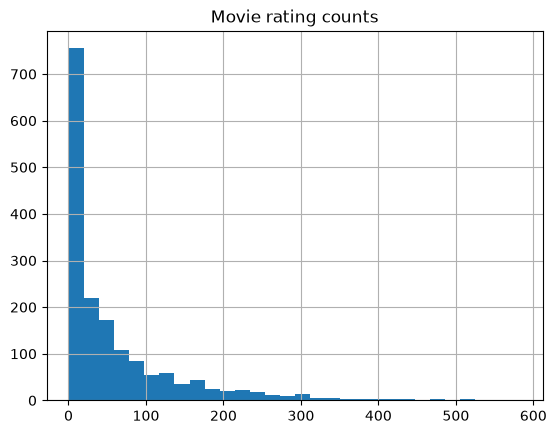

In [3]:
all_ratings = pd.merge(raw_ratings, items, on='item_id', how='inner')
popularity = all_ratings.groupby('item_id').size().reset_index(name='popularity')
items = pd.merge(items, popularity, on='item_id', how='left')
items['popularity'] = items['popularity'].fillna(0).astype(int)
all_ratings = pd.merge(all_ratings, popularity, on='item_id', how='left')
indexed_items = items.set_index('item_id')
display(all_ratings.describe())
print('Movies rated only once:', (items['popularity'] == 1).sum())
display(items.nlargest(10, 'popularity')[['title', 'popularity']])
items['popularity'].hist(bins=30)
plt.title('Movie rating counts')
plt.show()

## 3. Completed Quick Exercise: Average rating by movie

In [4]:
average_ratings = (all_ratings.groupby(['item_id', 'title'])['rating']
                   .agg(['mean', 'count']).reset_index()
                   .rename(columns={'mean': 'average_rating', 'count': 'rating_count'}))
display(average_ratings.sort_values('average_rating', ascending=False).head(10))
print('Note: a movie with only one rating can have an extreme average.')

,item_id,title,average_rating,rating_count
813,814,"Great Day in Harlem, A (1994)",5.0,1
1598,1599,Someone Else's America (1995),5.0,1
1200,1201,Marlene Dietrich: Shadow and Light (1996),5.0,1
1121,1122,They Made Me a Criminal (1939),5.0,1
1652,1653,Entertaining Angels: The Dorothy Day Story (1996),5.0,1
1292,1293,Star Kid (1997),5.0,3
1499,1500,Santa with Muscles (1996),5.0,2
1188,1189,Prefontaine (1997),5.0,3
1535,1536,Aiqing wansui (1994),5.0,1
1466,1467,"Saint of Fort Washington, The (1993)",5.0,2


Note: a movie with only one rating can have an extreme average.


## 4. Train/test split and collaborative-filtering embedding model

In [5]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Embedding, Flatten, Dot, Dense, Concatenate, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error, mean_absolute_error

ratings_train, ratings_test = train_test_split(all_ratings, test_size=0.2,
                                               random_state=0)
user_id_train = ratings_train['user_id'].to_numpy(dtype='int32')
item_id_train = ratings_train['item_id'].to_numpy(dtype='int32')
rating_train = ratings_train['rating'].to_numpy(dtype='float32')
user_id_test = ratings_test['user_id'].to_numpy(dtype='int32')
item_id_test = ratings_test['item_id'].to_numpy(dtype='int32')
rating_test = ratings_test['rating'].to_numpy(dtype='float32')
max_user_id = int(all_ratings['user_id'].max())
max_item_id = int(all_ratings['item_id'].max())
print('Train:', len(rating_train), 'Test:', len(rating_test))

Train: 80000 Test: 20000


In [6]:
class RegressionModel(Model):
    def __init__(self, embedding_size, max_user_id, max_item_id):
        super().__init__()
        self.user_embedding = Embedding(max_user_id + 1, embedding_size, name='user_embedding')
        self.item_embedding = Embedding(max_item_id + 1, embedding_size, name='item_embedding')
        self.flatten = Flatten()
        self.dot = Dot(axes=1)

    def call(self, inputs):
        user_ids, item_ids = inputs
        user_vectors = self.flatten(self.user_embedding(user_ids))
        item_vectors = self.flatten(self.item_embedding(item_ids))
        return self.dot([user_vectors, item_vectors])

model = RegressionModel(embedding_size=64, max_user_id=max_user_id,
                        max_item_id=max_item_id)
model.compile(optimizer=Adam(), loss='mae')
history = model.fit([user_id_train, item_id_train], rating_train,
                    batch_size=64, epochs=10, validation_split=0.1,
                    shuffle=True, verbose=1)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 2.6386 - val_loss: 1.0498
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8518 - val_loss: 0.7974
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.7522 - val_loss: 0.7687
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.7228 - val_loss: 0.7571
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.6993 - val_loss: 0.7502
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.6776 - val_loss: 0.7474
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.6558 - val_loss: 0.7440
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.6329 - val_loss: 0.7441
Epoch 9/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.6086 - val_loss: 0.7442
Epoch 10/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.5824 - val_loss: 0.7446


## 5. Overfitting questions (answer from the actual loss curves)

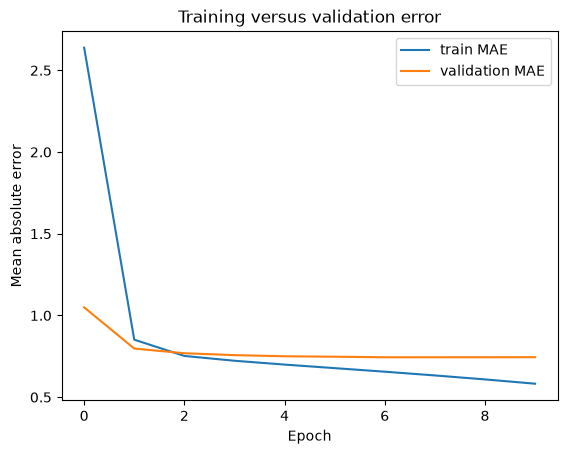

Test MSE: 0.9181362986564636
Test MAE: 0.737933337688446


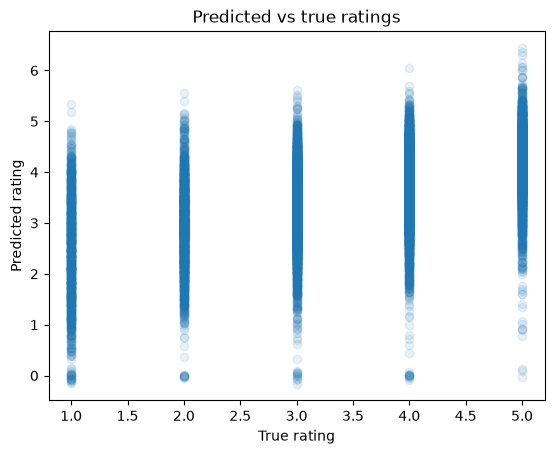

In [7]:
plt.plot(history.history['loss'], label='train MAE')
plt.plot(history.history['val_loss'], label='validation MAE')
plt.xlabel('Epoch')
plt.ylabel('Mean absolute error')
plt.title('Training versus validation error')
plt.legend()
plt.show()

test_preds = model.predict([user_id_test, item_id_test], verbose=0).ravel()
print('Test MSE:', mean_squared_error(rating_test, test_preds))
print('Test MAE:', mean_absolute_error(rating_test, test_preds))
plt.scatter(rating_test, test_preds, alpha=0.1)
plt.xlabel('True rating')
plt.ylabel('Predicted rating')
plt.title('Predicted vs true ratings')
plt.show()

**Written answer — overfitting:** Overfitting is suggested if training loss keeps falling while validation loss stops improving or rises. Determine whether this occurred from your plotted curves; the outcome cannot be known before execution. **How to prevent it:** Try reducing embedding size, adding dropout or regularization, using early stopping, and/or fewer training epochs. Keep a held-out test set for final evaluation.

## 6. Inspect embeddings and compute similarity

In [8]:
user_embeddings = model.user_embedding.get_weights()[0]
item_embeddings = model.item_embedding.get_weights()[0]
print('User embedding matrix:', user_embeddings.shape)
print('Movie embedding matrix:', item_embeddings.shape)
example_id = 181
print('Movie:', indexed_items.loc[example_id, 'title'])
print('Movie embedding shape:', item_embeddings[example_id].shape)

from sklearn.metrics.pairwise import cosine_similarity

def cosine(a, b):
    return float(cosine_similarity(np.asarray(a).reshape(1, -1),
                                   np.asarray(b).reshape(1, -1))[0, 0])

def print_similarity(item_a, item_b):
    print(indexed_items.loc[item_a, 'title'])
    print(indexed_items.loc[item_b, 'title'])
    print('Cosine similarity:', round(cosine(item_embeddings[item_a],
                                            item_embeddings[item_b]), 3))

print_similarity(50, 181)
print_similarity(181, 288)
print_similarity(181, 1)

User embedding matrix: (944, 64)
Movie embedding matrix: (1683, 64)
Movie: Return of the Jedi (1983)
Movie embedding shape: (64,)
Star Wars (1977)
Return of the Jedi (1983)
Cosine similarity: 0.917
Return of the Jedi (1983)
Scream (1996)
Cosine similarity: 0.625
Return of the Jedi (1983)
Toy Story (1995)
Cosine similarity: 0.82


## 7. Completed Quick Exercise: Compare similar and dissimilar movies

In [9]:
# Compare an example movie with every other title, excluding itself.
reference_id = 50
ids = np.array(indexed_items.index, dtype=int)
valid_ids = ids[ids < len(item_embeddings)]
reference_vector = item_embeddings[reference_id].reshape(1, -1)
all_similarities = cosine_similarity(reference_vector, item_embeddings[valid_ids]).ravel()
ranked = pd.DataFrame({'item_id': valid_ids, 'cosine_similarity': all_similarities})
ranked = ranked[ranked.item_id != reference_id]
ranked['title'] = ranked['item_id'].map(indexed_items['title'])
print('Most similar to:', indexed_items.loc[reference_id, 'title'])
display(ranked.nlargest(5, 'cosine_similarity'))
print('Least similar in learned embedding space:')
display(ranked.nsmallest(5, 'cosine_similarity'))

Most similar to: Star Wars (1977)


,item_id,cosine_similarity,title
180,181,0.916796,Return of the Jedi (1983)
171,172,0.887038,"Empire Strikes Back, The (1980)"
227,228,0.855313,Star Trek: The Wrath of Khan (1982)
175,176,0.854943,Aliens (1986)
1600,1601,0.844395,Office Killer (1997)


Least similar in learned embedding space:


,item_id,cosine_similarity,title
1491,1492,-0.283888,Window to Paris (1994)
1509,1510,-0.217674,Mad Dog Time (1996)
1431,1432,-0.212134,"Mighty, The (1998)"
1307,1308,-0.186962,Babyfever (1994)
1363,1364,-0.154196,Bird of Prey (1996)


**Interpretation:** The learned embedding similarity comes from co-rating patterns, not movie plot descriptions. A pair can be close in the embedding space even if the titles look unrelated. Check the actual displayed movies and explain whether they make sense to you.

## 8. Most-similar movies and t-SNE visualization

In [10]:
def most_similar(item_id, top_n=10):
    valid_ids = np.array(indexed_items.index, dtype=int)
    valid_ids = valid_ids[valid_ids < len(item_embeddings)]
    similarities = cosine_similarity(item_embeddings[item_id].reshape(1, -1),
                                     item_embeddings[valid_ids]).ravel()
    candidate_ids = valid_ids[valid_ids != item_id]
    candidate_scores = similarities[valid_ids != item_id]
    order = np.argsort(candidate_scores)[::-1][:top_n]
    return [(int(candidate_ids[i]), indexed_items.loc[int(candidate_ids[i]), 'title'],
             float(candidate_scores[i])) for i in order]

most_similar(50, top_n=10)

[(181, 'Return of the Jedi (1983)', 0.9167963266372681),
 (172, 'Empire Strikes Back, The (1980)', 0.8870376944541931),
 (228, 'Star Trek: The Wrath of Khan (1982)', 0.8553128838539124),
 (176, 'Aliens (1986)', 0.8549425601959229),
 (1601, 'Office Killer (1997)', 0.8443949222564697),
 (151, 'Willy Wonka and the Chocolate Factory (1971)', 0.8422308564186096),
 (1528, 'Nowhere (1997)', 0.8414108753204346),
 (1063, 'Little Princess, A (1995)', 0.8361784219741821),
 (195, 'Terminator, The (1984)', 0.8357298374176025),
 (234, 'Jaws (1975)', 0.8312737941741943)]

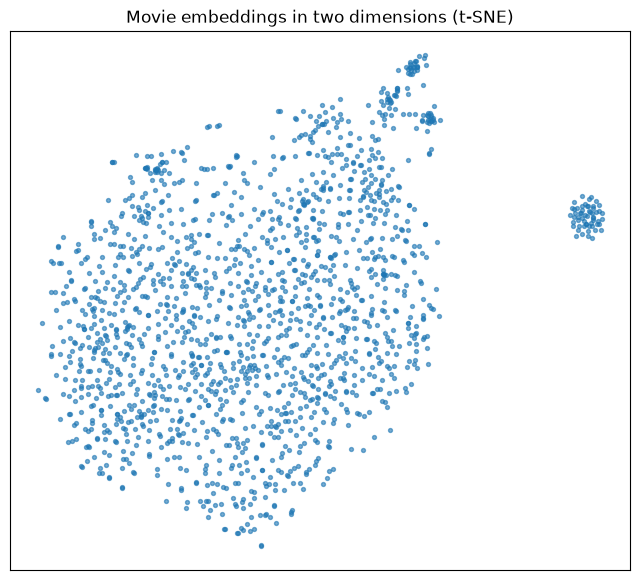

In [11]:
from sklearn.manifold import TSNE
# Visualize only actual movies; ID zero is unused.
embedding_points = item_embeddings[np.array(indexed_items.index, dtype=int)]
item_tsne = TSNE(n_components=2, learning_rate='auto',
                 init='pca', perplexity=30, random_state=42).fit_transform(embedding_points)
plt.figure(figsize=(8, 7))
plt.scatter(item_tsne[:, 0], item_tsne[:, 1], s=8, alpha=0.6)
plt.title('Movie embeddings in two dimensions (t-SNE)')
plt.xticks([])
plt.yticks([])
plt.show()

## 9. Completed exercises: Add hidden layers, dropout and compare test MAE

In [12]:
class ImprovedRegressionModel(Model):
    def __init__(self, embedding_size, max_user_id, max_item_id, dropout_rate=0.2,
                 hidden_size=32):
        super().__init__()
        self.user_embedding = Embedding(max_user_id + 1, embedding_size)
        self.item_embedding = Embedding(max_item_id + 1, embedding_size)
        self.flatten = Flatten()
        self.concat = Concatenate()
        self.hidden = Dense(hidden_size, activation='relu')
        self.dropout = Dropout(dropout_rate)
        self.output_layer = Dense(1)

    def call(self, inputs, training=False):
        users, movies = inputs
        user_vec = self.flatten(self.user_embedding(users))
        movie_vec = self.flatten(self.item_embedding(movies))
        hidden = self.hidden(self.concat([user_vec, movie_vec]))
        return self.output_layer(self.dropout(hidden, training=training))

experiment_results = []
for embedding_size, dropout in [(16, 0.0), (16, 0.2), (32, 0.3)]:
    candidate = ImprovedRegressionModel(embedding_size, max_user_id, max_item_id,
                                        dropout_rate=dropout, hidden_size=32)
    candidate.compile(optimizer=Adam(learning_rate=0.001), loss='mae')
    candidate.fit([user_id_train, item_id_train], rating_train,
                  batch_size=128, epochs=5, validation_split=0.1,
                  shuffle=True, verbose=0)
    predictions = candidate.predict([user_id_test, item_id_test], verbose=0).ravel()
    mae = mean_absolute_error(rating_test, predictions)
    experiment_results.append({'embedding_size': embedding_size,
                               'dropout': dropout, 'test_MAE': mae})
    print(f'Embedding {embedding_size}, dropout {dropout}: test MAE {mae:.3f}')
experiment_table = pd.DataFrame(experiment_results)
display(experiment_table.sort_values('test_MAE'))
print('Baseline model test MAE:', mean_absolute_error(rating_test, test_preds))

Embedding 16, dropout 0.0: test MAE 0.743
Embedding 16, dropout 0.2: test MAE 0.747
Embedding 32, dropout 0.3: test MAE 0.745


,embedding_size,dropout,test_MAE
0,16,0.0,0.743391
2,32,0.3,0.745309
1,16,0.2,0.746752


Baseline model test MAE: 0.737933337688446


**Written answer — model improvement:** The completed exercise compares three architectures with different embedding sizes and dropout rates. A lower test MAE indicates a better fit on this split, but changing an architecture does not guarantee improvement. State the **best observed** MAE from the table after executing the notebook; no number is assumed.

## 10. Generate recommendations for a user

In [13]:
def recommend(user_id, top_n=10, fitted_model=None):
    fitted_model = model if fitted_model is None else fitted_model
    already_seen = set(all_ratings.loc[all_ratings['user_id'] == user_id, 'item_id'])
    candidates = [int(mid) for mid in indexed_items.index if int(mid) not in already_seen]
    if not candidates:
        return []
    users = np.full(len(candidates), user_id, dtype='int32')
    movies = np.array(candidates, dtype='int32')
    predicted = fitted_model.predict([users, movies], verbose=0).reshape(-1)
    top_indices = np.argsort(predicted)[-top_n:][::-1]
    return [(indexed_items.loc[candidates[i], 'title'], float(predicted[i]))
            for i in top_indices]

for title, predicted_rating in recommend(5):
    print(f'{predicted_rating:.2f}: {title}')

3.95: Schindler's List (1993)
3.94: One Flew Over the Cuckoo's Nest (1975)
3.89: Santa with Muscles (1996)
3.89: Pulp Fiction (1994)
3.87: Terminator, The (1984)
3.80: Wallace & Gromit: The Best of Aardman Animation (1996)
3.79: Usual Suspects, The (1995)
3.77: Manon of the Spring (Manon des sources) (1986)
3.73: Beautiful Thing (1996)
3.73: Godfather: Part II, The (1974)
